 Градиентный бустинг. AdaBoost

Реализация градиентного бустинга для разного количества деревьев

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

In [ ]:
# Загрузка датасета
data = load_diabetes()
X = data.data
y = data.target

In [ ]:
# Разделение данных на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Количество деревьев
n_trees = [2, 5, 10, 20, 50]
train_errors = []
test_errors = []

# Обучение моделей и вычисление MSE
for n in n_trees:
    model = GradientBoostingRegressor(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)

    # Прогнозирование
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Вычисление MSE
    train_error = mean_squared_error(y_train, y_train_pred)
    test_error = mean_squared_error(y_test, y_test_pred)

    train_errors.append(train_error)
    test_errors.append(test_error)

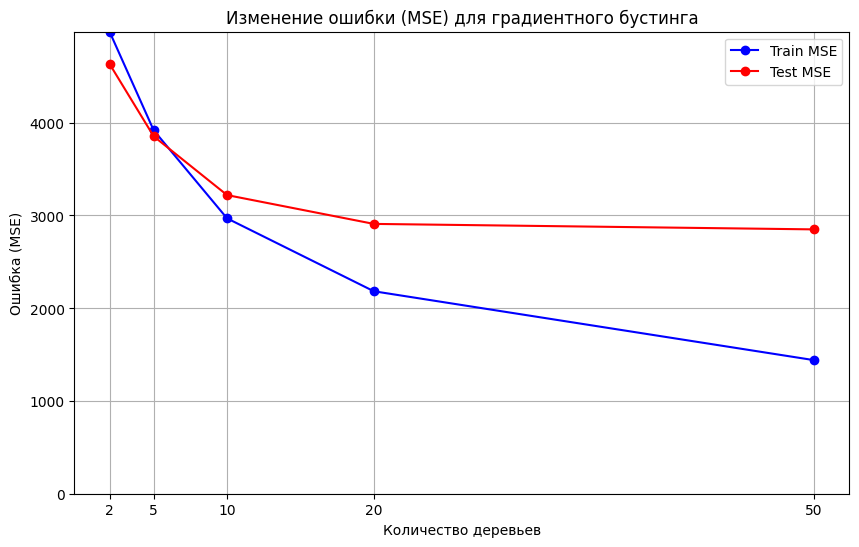

In [ ]:
# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(n_trees, train_errors, marker='o', label='Train MSE', color='blue')
plt.plot(n_trees, test_errors, marker='o', label='Test MSE', color='red')
plt.title('Изменение ошибки (MSE) для градиентного бустинга')
plt.xlabel('Количество деревьев')
plt.ylabel('Ошибка (MSE)')
plt.xticks(n_trees)
plt.ylim(0, max(max(train_errors), max(test_errors)) + 1)
plt.legend()
plt.grid()
plt.show()

---
Реализация градиентного бустинга для деревьев разной глубины вложенности

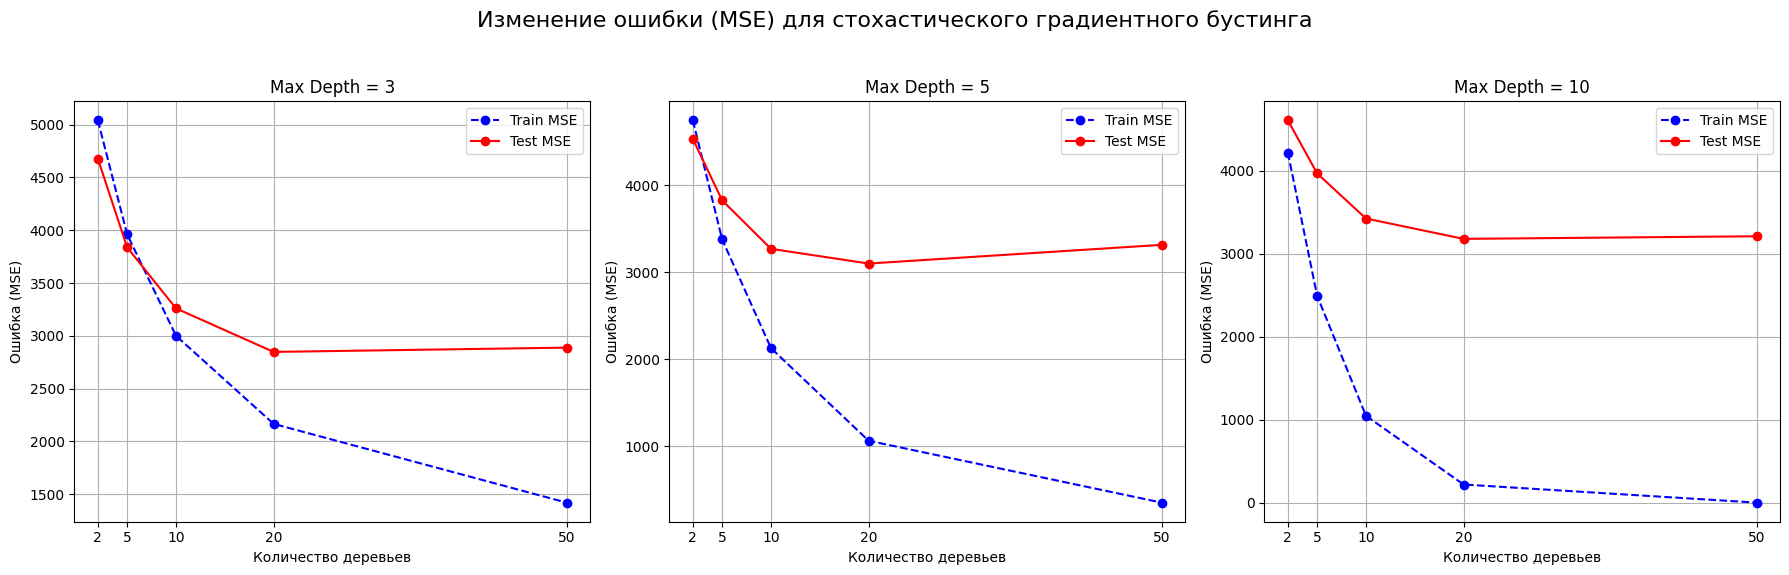

In [ ]:
# Количество деревьев и глубина дерева
n_trees = [2, 5, 10, 20, 50]
max_depths = [3, 5, 10]  # Уровни глубины дерева
subsample = 0.8  # Доля обучающей выборки для стохастического градиентного бустинга

# Создание фигуры и подграфиков
fig, axs = plt.subplots(1, len(max_depths), figsize=(18, 6))

# Обучение моделей и вычисление MSE для каждой комбинации гиперпараметров
for idx, max_depth in enumerate(max_depths):
    train_errors = []
    test_errors = []

    for n in n_trees:
        model = GradientBoostingRegressor(n_estimators=n, max_depth=max_depth, subsample=subsample, random_state=42)
        model.fit(X_train, y_train)

        # Прогнозирование
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # Вычисление MSE
        train_error = mean_squared_error(y_train, y_train_pred)
        test_error = mean_squared_error(y_test, y_test_pred)

        train_errors.append(train_error)
        test_errors.append(test_error)

    # Построение графиков для каждого уровня глубины
    axs[idx].plot(n_trees, train_errors, marker='o', label='Train MSE', linestyle='--', color='blue')
    axs[idx].plot(n_trees, test_errors, marker='o', label='Test MSE', linestyle='-', color='red')
    axs[idx].set_title(f'Max Depth = {max_depth}')
    axs[idx].set_xlabel('Количество деревьев')
    axs[idx].set_ylabel('Ошибка (MSE)')
    axs[idx].set_xticks(n_trees)
    axs[idx].grid()
    axs[idx].legend()

plt.suptitle('Изменение ошибки (MSE) для стохастического градиентного бустинга', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Подгонка под заголовок
plt.show()

---
Проверим, как влияет на обучение скорость обучения


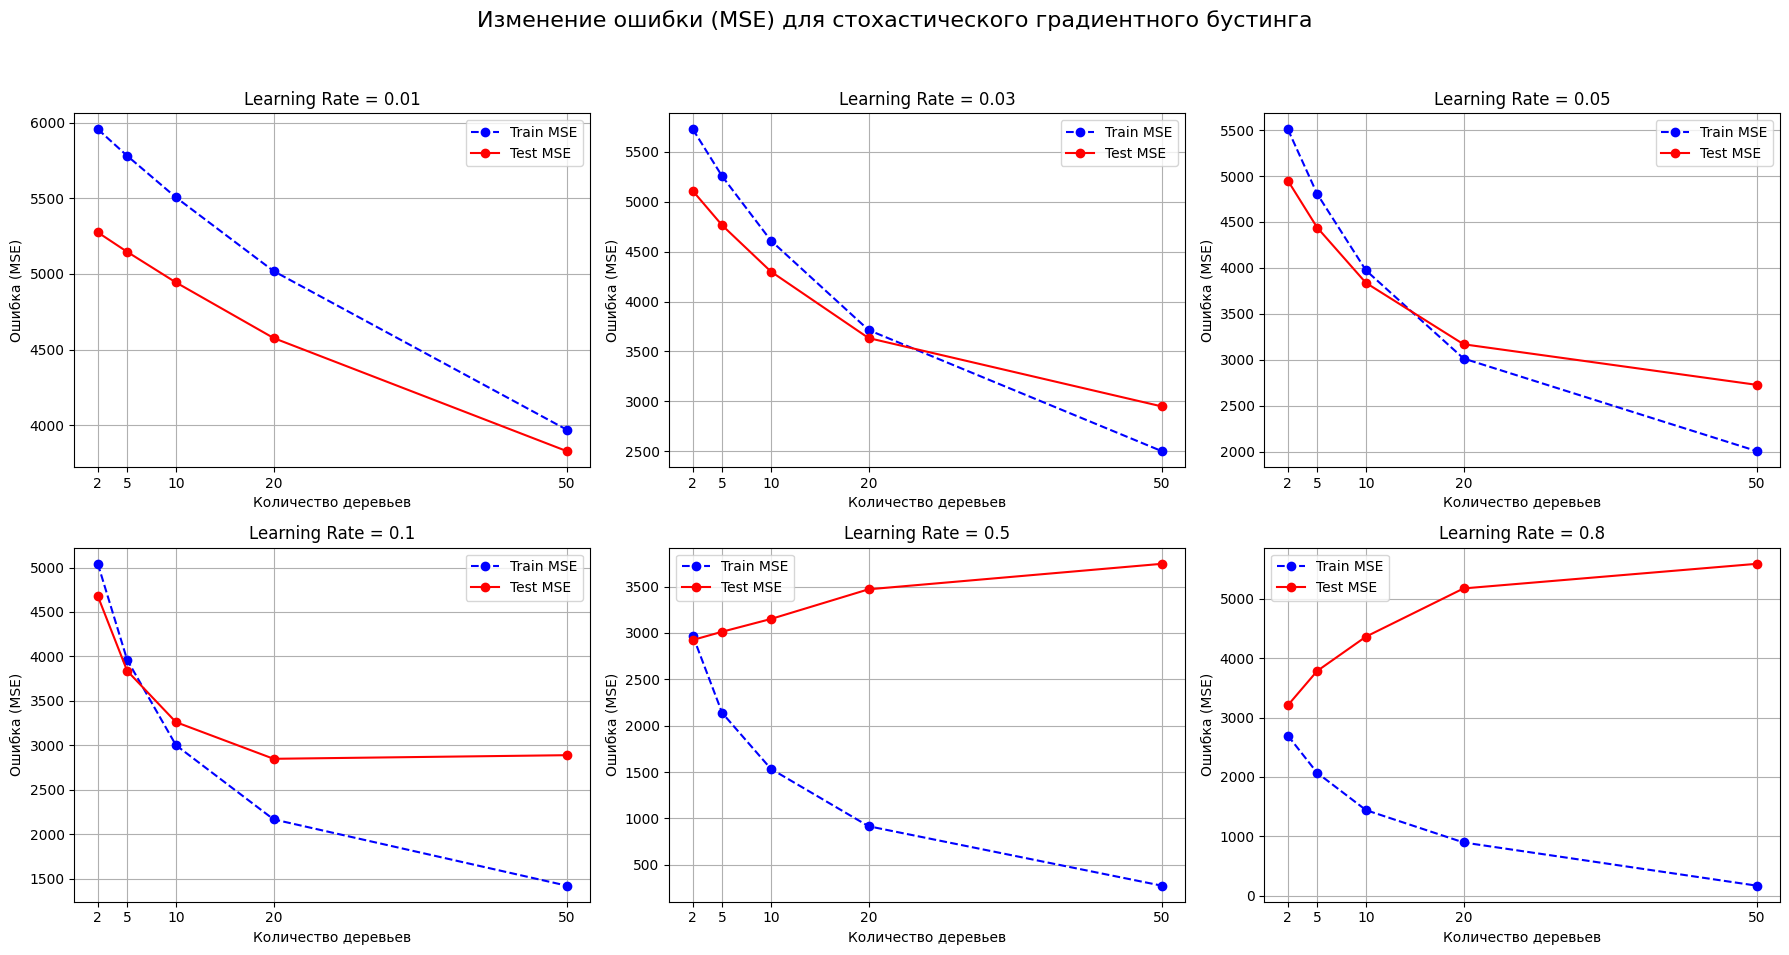

In [ ]:
# Количество деревьев и скорости обучения
n_trees = [2, 5, 10, 20, 50]
learning_rates = [0.01, 0.03, 0.05, 0.1, 0.5, 0.8]  # Скорости обучения
max_depth = 3  # Уровень глубины дерева
subsample = 0.8  # Доля обучающей выборки для стохастического градиентного бустинга

# Создание фигуры и подграфиков
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
axs = axs.flatten()  # Упрощаем индексацию подграфиков

# Обучение моделей и вычисление MSE для каждой комбинации скорости обучения
for idx, lr in enumerate(learning_rates):
    train_errors = []
    test_errors = []

    for n in n_trees:
        model = GradientBoostingRegressor(n_estimators=n, max_depth=max_depth, learning_rate=lr, subsample=subsample, random_state=42)
        model.fit(X_train, y_train)

        # Прогнозирование
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # Вычисление MSE
        train_error = mean_squared_error(y_train, y_train_pred)
        test_error = mean_squared_error(y_test, y_test_pred)

        train_errors.append(train_error)
        test_errors.append(test_error)

    # Построение графиков для каждой скорости обучения
    axs[idx].plot(n_trees, train_errors, marker='o', label='Train MSE', linestyle='--', color='blue')
    axs[idx].plot(n_trees, test_errors, marker='o', label='Test MSE', linestyle='-', color='red')
    axs[idx].set_title(f'Learning Rate = {lr}')
    axs[idx].set_xlabel('Количество деревьев')
    axs[idx].set_ylabel('Ошибка (MSE)')
    axs[idx].set_xticks(n_trees)
    axs[idx].grid()
    axs[idx].legend()

plt.suptitle('Изменение ошибки (MSE) для стохастического градиентного бустинга', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Подгонка под заголовок
plt.show()


---
Реализация стохастического градиентного бустинга

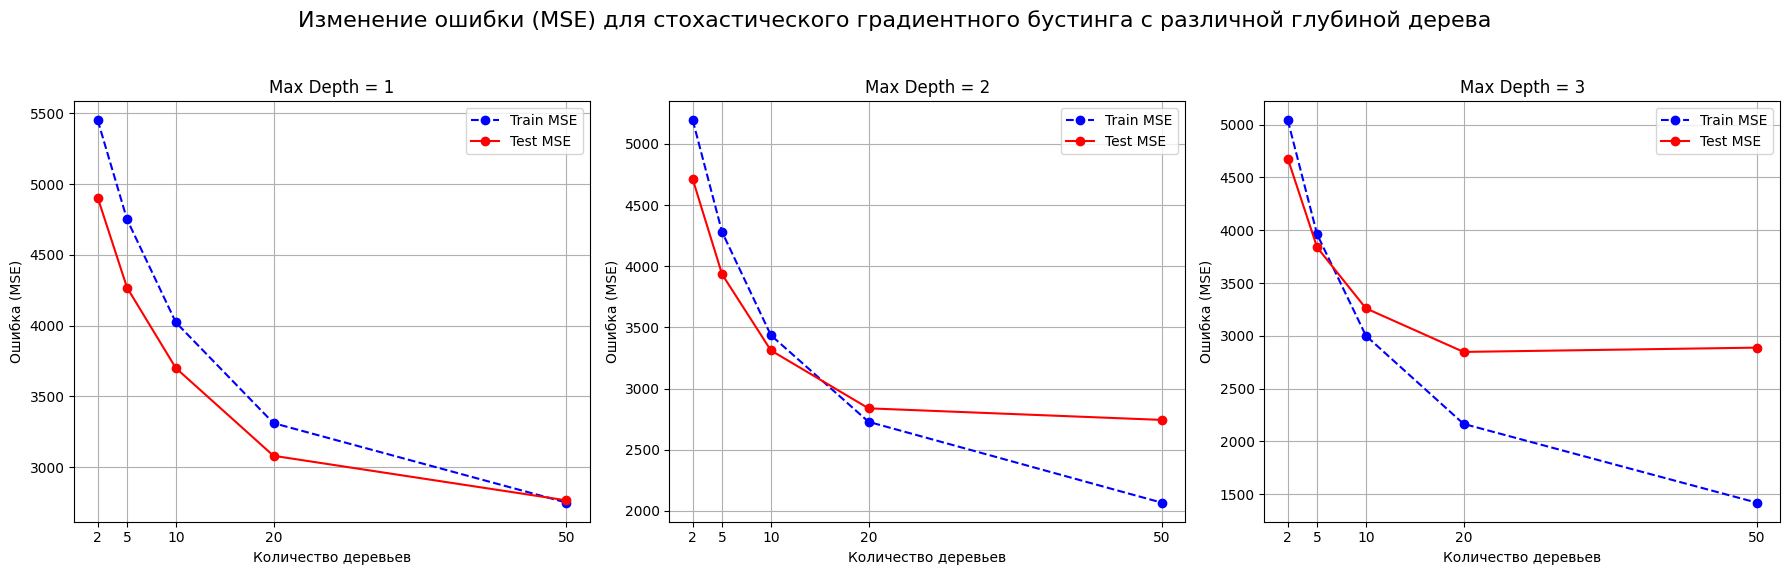

In [ ]:
# Количество деревьев и глубина дерева
n_trees = [2, 5, 10, 20, 50]
max_depths = [1, 2, 3]  # Примеры глубины дерева
subsample = 0.8  # Доля обучающей выборки для стохастического градиентного бустинга

# Создание фигуры и подграфиков
fig, axs = plt.subplots(1, len(max_depths), figsize=(18, 6))

# Обучение моделей и вычисление MSE для каждой комбинации гиперпараметров
for idx, max_depth in enumerate(max_depths):
    train_errors = []
    test_errors = []

    for n in n_trees:
        model = GradientBoostingRegressor(n_estimators=n, max_depth=max_depth, subsample=subsample, random_state=42)
        model.fit(X_train, y_train)

        # Прогнозирование
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # Вычисление MSE
        train_error = mean_squared_error(y_train, y_train_pred)
        test_error = mean_squared_error(y_test, y_test_pred)

        train_errors.append(train_error)
        test_errors.append(test_error)

    # Построение графиков для каждой глубины дерева
    axs[idx].plot(n_trees, train_errors, marker='o', label='Train MSE', linestyle='--', color='blue')
    axs[idx].plot(n_trees, test_errors, marker='o', label='Test MSE', linestyle='-', color='red')
    axs[idx].set_title(f'Max Depth = {max_depth}')
    axs[idx].set_xlabel('Количество деревьев')
    axs[idx].set_ylabel('Ошибка (MSE)')
    axs[idx].set_xticks(n_trees)
    axs[idx].grid()
    axs[idx].legend()

plt.suptitle('Изменение ошибки (MSE) для стохастического градиентного бустинга с различной глубиной дерева', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Подгонка под заголовок
plt.show()

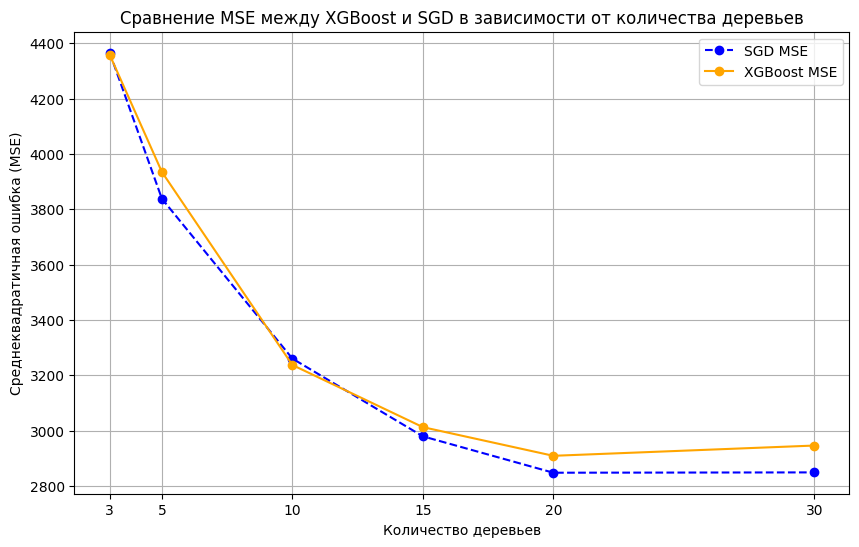

In [ ]:
import xgboost as xgb

# Количество деревьев для сравнения
n_trees = [3, 5, 10, 15, 20, 30]

# Словари для хранения ошибок
sgb_errors = []
xgb_errors = []

# Обучение и вычисление MSE для стохастического градиентного бустинга
for n in n_trees:
    sgb_model = GradientBoostingRegressor(n_estimators=n, max_depth=3, learning_rate=0.1, subsample=0.8, random_state=42)
    sgb_model.fit(X_train, y_train)
    y_sgb_pred = sgb_model.predict(X_test)
    sgb_mse = mean_squared_error(y_test, y_sgb_pred)
    sgb_errors.append(sgb_mse)

# Обучение и вычисление MSE для XGBoost
for n in n_trees:
    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)
    xgb_params = {
        'objective': 'reg:squarederror',
        'max_depth': 3,
        'learning_rate': 0.1,
        'n_estimators': n,
        'subsample': 0.8
    }
    xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=n)
    y_xgb_pred = xgb_model.predict(dtest)
    xgb_mse = mean_squared_error(y_test, y_xgb_pred)
    xgb_errors.append(xgb_mse)

# Построение графика сравнения MSE
plt.figure(figsize=(10, 6))
plt.plot(n_trees, sgb_errors, marker='o', label='SGD MSE', linestyle='--', color='blue')
plt.plot(n_trees, xgb_errors, marker='o', label='XGBoost MSE', linestyle='-', color='orange')
plt.title('Сравнение MSE между XGBoost и SGD в зависимости от количества деревьев')
plt.xlabel('Количество деревьев')
plt.ylabel('Среднеквадратичная ошибка (MSE)')
plt.xticks(n_trees)
plt.grid()
plt.legend()
plt.show()

## AdaBoost<a class='anchor' id='ada'>


Для задачи бинарной классификации он заключается в использовании слабых классификаторов (например, деревьев глубиной 1 - так называемых "пней") в цикле, с придаванием объектам весов. После каждого шага итерации, когда разделяющая плоскость классификатора делит пространство объектов на две части, веса объектов перераспределяются, и веса неправильно классифицированных объектов увеличиваются, чтобы на следующей итерации классификатор акцентировался на этих объектах. Классификатору также присваивается вес в зависимости от его точности. Затем полученные деревья с весами объединяются в один сильный классификатор. В этом и заключается адаптивность алгоритма. Алгоритм AdaBoost также называют алгоритмом усиления классификаторов.

**Продемонстрируем работу AdaBoost**

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_breast_cancer

In [ ]:
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
X.shape, y.shape

((569, 30), (569,))

In [ ]:
import numpy as np
np.random.seed(6)
index = np.random.randint(0, X.shape[0], 1)
X_test = X.loc[index]
y_test = y.loc[index]

In [ ]:
X.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object')

In [ ]:
X = X.loc[[ 41,  44,  73,  81,  89,  91, 135, 146, 484, 491]]
y = y.loc[[ 41,  44,  73,  81,  89,  91, 135, 146, 484, 491]]
X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
41,10.95,21.35,71.90,371.1,0.12270,0.12180,0.10440,0.05669,0.1895,0.06870,...,12.84,35.34,87.22,514.0,0.19090,0.26980,0.4023,0.14240,0.2964,0.09606
44,13.17,21.81,85.42,531.5,0.09714,0.10470,0.08259,0.05252,0.1746,0.06177,...,16.23,29.89,105.50,740.7,0.15030,0.39040,0.3728,0.16070,0.3693,0.09618
73,13.80,15.79,90.43,584.1,0.10070,0.12800,0.07789,0.05069,0.1662,0.06566,...,16.57,20.86,110.30,812.4,0.14110,0.35420,0.2779,0.13830,0.2589,0.10300
81,13.34,15.86,86.49,520.0,0.10780,0.15350,0.11690,0.06987,0.1942,0.06902,...,15.53,23.19,96.66,614.9,0.15360,0.47910,0.4858,0.17080,0.3527,0.10160
89,14.64,15.24,95.77,651.9,0.11320,0.13390,0.09966,0.07064,0.2116,0.06346,...,16.34,18.24,109.40,803.6,0.12770,0.30890,0.2604,0.13970,0.3151,0.08473
91,15.37,22.76,100.20,728.2,0.09200,0.10360,0.11220,0.07483,0.1717,0.06097,...,16.43,25.84,107.50,830.9,0.12570,0.19970,0.2846,0.14760,0.2556,0.06828
135,12.77,22.47,81.72,506.3,0.09055,0.05761,0.04711,0.02704,0.1585,0.06065,...,14.49,33.37,92.04,653.6,0.14190,0.15230,0.2177,0.09331,0.2829,0.08067
146,11.80,16.58,78.99,432.0,0.10910,0.17000,0.16590,0.07415,0.2678,0.07371,...,13.74,26.38,91.93,591.7,0.13850,0.40920,0.4504,0.18650,0.5774,0.10300
484,15.73,11.28,102.80,747.2,0.10430,0.12990,0.11910,0.06211,0.1784,0.06259,...,17.01,14.20,112.50,854.3,0.15410,0.29790,0.4004,0.14520,0.2557,0.08181
491,17.85,13.23,114.60,992.1,0.07838,0.06217,0.04445,0.04178,0.1220,0.05243,...,19.82,18.42,127.10,1210.0,0.09862,0.09976,0.1048,0.08341,0.1783,0.05871


In [ ]:
y

,target
41,0
44,0
73,0
81,1
89,1
91,0
135,0
146,0
484,1
491,1


__1.__ Инициализация начальных весов объектов из выборки длиной $l$:

$$D_{1}(i) = \frac{1}{l}$$

In [ ]:
n_objects = X.shape[0]
w = np.ones(n_objects) / n_objects
w

array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])

__2.__ Для каждого из $N$ деревьев в ансамбле:

- находим классификатор $b_{n}$, который минимизирует взвешенную ошибку классификации

$$b_{n} = \underset{b}{\text{argmin}}\;\varepsilon_{j},$$

    где

$$\varepsilon_{j} = \sum_{i=1}^{l}D_{n}(i)[y_{i}\neq b_{j}(x)]$$

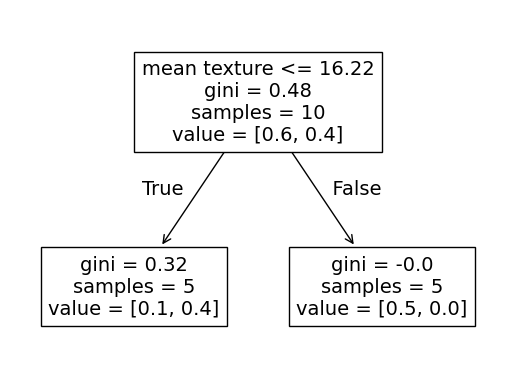

In [ ]:
stump1 = DecisionTreeClassifier(max_depth=1, random_state=1)
stump1.fit(X, y, sample_weight=w)

pred = stump1.predict(X)
plot_tree(stump1, feature_names=X.columns, );

In [ ]:
pred == y

,target
41,True
44,True
73,False
81,True
89,True
91,True
135,True
146,True
484,True
491,True


In [ ]:
error1 = sum(pred != y) / len(y)
error1

0.1

- критерием остановки является значение $\varepsilon_{j} \geq 0.5$. При таком значении ошибки нужно выбрать другой классификатор и продолжить.

- выбираем вес для дерева $\alpha_{n}$ по формуле

$$\alpha_{n} = \frac{1}{2}\text{ln}\frac{1 - \varepsilon_{n}}{\varepsilon_{n}}$$


In [ ]:
def amount_of_say(x):
    return 1/2 * np.log((1 - x) / x)

<ipython-input-60-d4f702aa4b94>:2: RuntimeWarning: divide by zero encountered in scalar divide
  return 1/2 * np.log((1 - x) / x)
<ipython-input-60-d4f702aa4b94>:2: RuntimeWarning: divide by zero encountered in log
  return 1/2 * np.log((1 - x) / x)


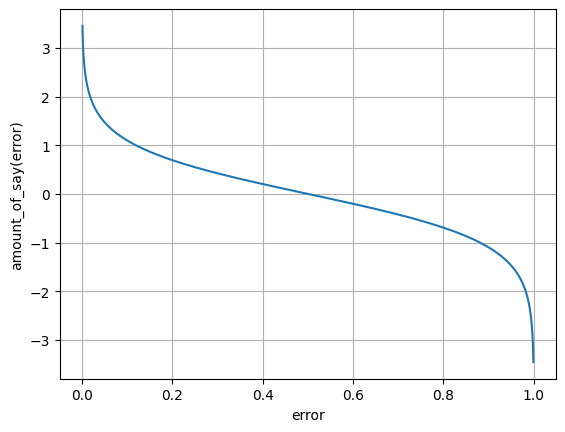

In [ ]:
import matplotlib.pyplot as plt
dots = np.linspace(0, 1, 1000)
amount_of_say_value = list(map(amount_of_say, dots))

plt.xlabel('error')
plt.ylabel('amount_of_say(error)')
plt.grid()
plt.plot(dots, amount_of_say_value);

**Получим вес для пня**

In [ ]:
alpha1 = 1/2 * np.log((1 - error1) / error1)
alpha1

1.0986122886681098

- обновляем веса при объектах:
$$D_i = D_{i-1}e^{\alpha_i} - \text{изменение веса одного объекта при неверной классификации} $$

In [ ]:
def new_sample_weight(x):
    return np.exp(x)

Если пень сделал не очень хорошую классификацию, то вес объекта станет немного больше, если пень сделал хорошую классификацию, то вес объекта станет больше.

**Меняем вес неверно классифицированного объекта**

In [ ]:
wrong_mask = pred != y
w[wrong_mask] = w[wrong_mask] * np.exp(alpha1)
w

array([0.1, 0.1, 0.3, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])

$$D_i = D_{i-1}e^{-\alpha_i} - \text{изменение веса одного объекта при верной классификации} $$

In [ ]:
def new_sample_weight(x):
    return np.exp(-x)

Если пень сделал не очень хорошую классификацию, то вес объекта станет меньше, если пень сделал хорошую классификацию, то вес объекта станет немного меньше.

То есть, те объекты, которые хорошо классифицируются будут иметь меньший вес, чем те, на которых классификатор ошибается.

**Меняем веса верно классифицированных объектов**

In [ ]:
w[~wrong_mask] = w[~wrong_mask] * np.exp(-alpha1)
w

array([0.03333333, 0.03333333, 0.3       , 0.03333333, 0.03333333,
       0.03333333, 0.03333333, 0.03333333, 0.03333333, 0.03333333])

In [ ]:
sum(w)

0.6

In [ ]:
w /= sum(w)

In [ ]:
w

array([0.05555556, 0.05555556, 0.5       , 0.05555556, 0.05555556,
       0.05555556, 0.05555556, 0.05555556, 0.05555556, 0.05555556])

In [ ]:
sum(w)

1.0000000000000002

**Обучим следующий пень**

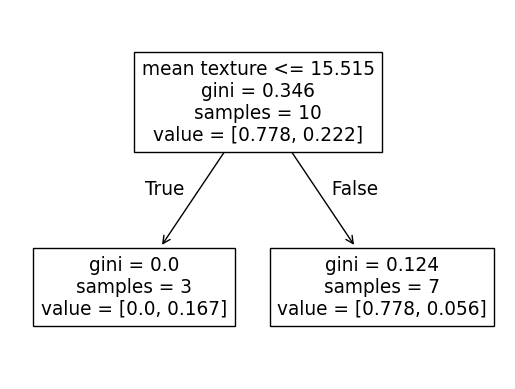

In [ ]:
stump2 = DecisionTreeClassifier(max_depth=1, random_state=1)
stump2.fit(X, y, sample_weight=w)

pred = stump2.predict(X)
plot_tree(stump2, feature_names=X.columns);

In [ ]:
pred != y

,target
41,False
44,False
73,False
81,True
89,False
91,False
135,False
146,False
484,False
491,False


In [ ]:
error2 = sum(pred != y) / len(y)
alpha2 = 1/2 * np.log((1 - error2) / error2)

wrong_mask = pred != y
w[wrong_mask] = w[wrong_mask] * np.exp(alpha2)

w[~wrong_mask] = w[~wrong_mask] * np.exp(-alpha2)
w /= sum(w)
w

array([0.03846154, 0.03846154, 0.34615385, 0.34615385, 0.03846154,
       0.03846154, 0.03846154, 0.03846154, 0.03846154, 0.03846154])

**Обучим следующий пень**

In [ ]:
stump3 = DecisionTreeClassifier(max_depth=1, random_state=1)
stump3.fit(X, y, sample_weight=w)

pred = stump3.predict(X)
error3 = sum(pred != y) / len(y)
alpha3 = 1/2 * np.log((1 - error3) / error3)
print(alpha3)
wrong_mask = pred != y
w[wrong_mask] = w[wrong_mask] * np.exp(alpha3)

w[~wrong_mask] = w[~wrong_mask] * np.exp(-alpha3)
w /= sum(w)
w

0.6931471805599453


array([0.03125, 0.03125, 0.28125, 0.28125, 0.125  , 0.03125, 0.03125,
       0.03125, 0.03125, 0.125  ])

In [ ]:
wrong_mask

,target
41,False
44,False
73,False
81,False
89,True
91,False
135,False
146,False
484,False
491,True


**Предскажем классы объектов с помощью трех пней**

In [ ]:
display(X_test, y_test)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
227,15.0,15.51,97.45,684.5,0.08371,0.1096,0.06505,0.0378,0.1881,0.05907,...,16.41,19.31,114.2,808.2,0.1136,0.3627,0.3402,0.1379,0.2954,0.08362


,target
227,1


In [ ]:
alpha1, alpha2, alpha3

(1.0986122886681098, 1.0986122886681098, 0.6931471805599453)

In [ ]:
pred1 = stump1.predict(X_test)
pred2 = stump2.predict(X_test)
pred3 = stump3.predict(X_test)
pred1, pred2, pred3

(array([1]), array([1]), array([0]))

In [ ]:
alpha1 + alpha2, alpha3

(2.1972245773362196, 0.6931471805599453)

In [ ]:
pred = 1
y_test

,target
227,1


## Алгоритм AdaBoost<a class='anchor' id='alg_ada'>

__1.__ Инициализация начальных весов объектов из выборки длиной $l$ (равномерно):

$$D_{1}(i) = \frac{1}{l}$$

__2.__ Для каждого из $N$ деревьев в ансамбле:

- находим классификатор $b_{n}$, который минимизирует взвешенную ошибку классификации

$$b_{n} = \underset{b}{\text{argmin}}\;\varepsilon_{j},$$

    где

$$\varepsilon_{j} = \sum_{i=1}^{l}D_{n}(i)[y_{i}\neq b_{j}(x)]$$
$D_{n}(i)$ - вес объекта, $[y_{i}\neq b_{j}(x)]$ - неправильно классифицированные объекты

- критерием остановки является значение $\varepsilon_{j} \geq 0.5$. При таком значении ошибки нужно выбрать другой классификатор и продолжить.

- выбираем вес для дерева $\alpha_{n}$ по формуле

$$\alpha_{n} = \frac{1}{2}\text{ln}\frac{1 - \varepsilon_{n}}{\varepsilon_{n}}$$

- обновляем веса при объектах:

$$D_{n+1}(i) = \frac{D_{n}(i)e^{-\alpha_{n}y_{i}b_{n}(x_{i})}}{Z_{n}},$$

выражение $y_{i}b_{n}(x_{i})$ в случае $Y = \{-1, 1\}$ будет равняться 1 для правильно классифицированных объектов и -1 для неправильно классифицированных, то есть по сути правильность классификации будет означать, будет $e^{\alpha_{n}}$ стоять в числителе (увеличивается вес неправильно классиф. объектов) или в знаменателе (уменьшается вес правильно классиф. объектов) формулы. В случае $Y = \{0,1\}$ вес будет уменьшаться у правильно классифицированных объектов, а у неправильно классифицированных - оставаться неизменным (до нормализации). $Z_{n}$ здесь - нормализующий параметр, выбираемый так, чтобы $D_{n+1}$ по своей сути являлся распределением вероятностей, то есть

$$\sum_{i=1}^{l}D_{n+1} = 1.$$